# IP time vs frequency domain

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

In [2]:
# make the system setup. 
# these components are in the experiment module.

from em1d.experiment import *

tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

In [39]:
# make the forward operators
# these are in the forwards module

from em1d.forwards import *

times = torch.logspace(-5, -3, 32)
fwrTD = IPForward(tx, rx, times, tolerance=1e-5)

frqs = (torch.arange(32)+1)*2e3
fwrFD = IPForwardFD(tx, rx, frqs, tolerance=1e-5)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\em1d\src\em1d\experiment\experiment.py:108: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [40]:
rho = torch.tensor([40, 5, 300], dtype=torch.double)[:, None]
thickness = torch.tensor([20, 30], dtype=torch.double)[:, None]
tau = 1e-4*torch.ones(3, dtype=torch.double)[:, None]
c = 0.6*torch.ones(3, dtype=torch.double)[:, None]
c[1] = 0.9
m = torch.tensor([0.2, 0.5, 0.9], dtype=torch.double)[:, None]

plus_one = torch.zeros(10, dtype=torch.double)[None, :]

rho = rho+plus_one
tau = tau+plus_one
c = c+plus_one
m = m+plus_one
thickness = thickness+plus_one



dbdt = fwrTD(rho, tau,  m, c, thickness).real
Bfrq = fwrFD(rho, tau,  m, c, thickness)

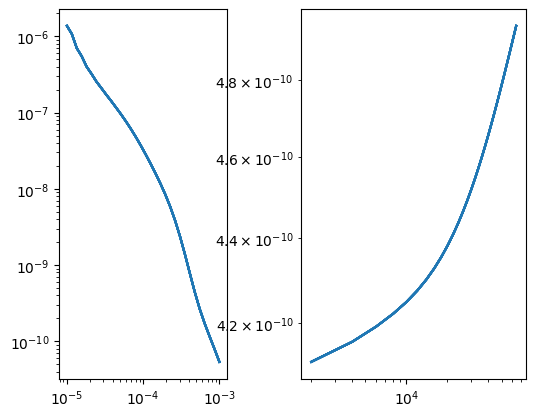

In [41]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(times, dbdt.T, 'C0')
axs[0].loglog(times,-dbdt.T, 'C0--')
axs[0].set_aspect('equal')
axs[1].loglog(frqs, torch.abs(Bfrq).T, 'C0');

In [42]:
from em1d.inversion import SmoothModelColeCole, FewLayerColeCole
from em1d.inversion import *

In [43]:
mtrue = FewLayerColeCole([40, 5, 300], [1e-4, 1e-4, 1e-4], [0.2, 0.5, 0.9], [0.6, 0.9, 0.6], [20, 30])
dbdt_true = fwrTD(*mtrue.mod).real
Bfrq_true = torch.abs(fwrFD(*mtrue.mod))

In [44]:
dbdt_err = dbdt_true*0.03
Bfrq_err = Bfrq_true*3e-5

dbdt_obs = dbdt_true + dbdt_err*torch.randn_like(dbdt_true)
Bfrq_obs = Bfrq_true + Bfrq_err*torch.randn_like(Bfrq_true)

In [45]:
mod_st = SmoothModelColeCole.starting_model(31, depth_bottom=100)

In [46]:
def transformFD(data):
    return torch.abs(data)

invTD   = Inversion(Bfrq_obs, Bfrq_err, mod_st, fwrFD, data_transform=transformFD)
res_mod = invTD.invert(smoothness=1e2, iter_cap=7)

torch.Size([124, 124])
001	misfit:	76.38
torch.Size([124, 124])
002	misfit:	50.08
torch.Size([124, 124])
increased max step
003	misfit:	14.06
torch.Size([124, 124])
increased max step
004	misfit:	2.86
torch.Size([124, 124])
increased max step
005	misfit:	2.16
torch.Size([124, 124])
increased max step
006	misfit:	1.66
torch.Size([124, 124])
increased max step
007	misfit:	1.30
reached iteration cap..
reached iteration cap..

 7


array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'chargeability'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

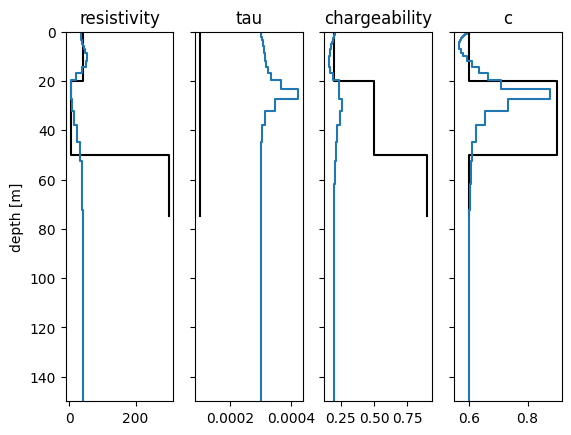

In [47]:
axs = mtrue.plot(color='k')
res_mod.plot(axs=axs)

In [48]:
def transformTD(data):
    return data.real

invTD = Inversion(dbdt_obs, dbdt_err, mod_st, fwrTD, data_transform=transformTD)
res_mod = invTD.invert(smoothness=1e2)

torch.Size([124, 124])
001	misfit:	9.65
torch.Size([124, 124])
002	misfit:	5.16
torch.Size([124, 124])
increased max step
003	misfit:	3.45
torch.Size([124, 124])
increased max step
004	misfit:	2.43
torch.Size([124, 124])
increased max step
005	misfit:	1.74
torch.Size([124, 124])
increased max step
006	misfit:	1.41
torch.Size([124, 124])
increased max step
007	misfit:	0.79
torch.Size([124, 124])
increased max step
008	misfit:	0.60
torch.Size([124, 124])
increased max step
009	misfit:	0.59
torch.Size([124, 124])
increased max step
010	misfit:	0.57
reached iteration cap..
reached iteration cap..

 10


array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'chargeability'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

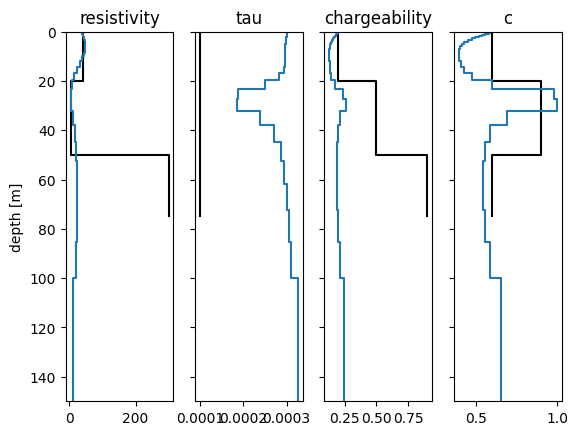

In [49]:
axs = mtrue.plot(color='k')
res_mod.plot(axs=axs)